Acurácia: 0.49666666666666665

Matriz de confusão:
[[126  49  29]
 [ 70  64  65]
 [ 31  58 108]]

Relatório:
              precision    recall  f1-score   support

           1       0.56      0.62      0.58       204
           2       0.37      0.32      0.35       199
           3       0.53      0.55      0.54       197

    accuracy                           0.50       600
   macro avg       0.49      0.50      0.49       600
weighted avg       0.49      0.50      0.49       600



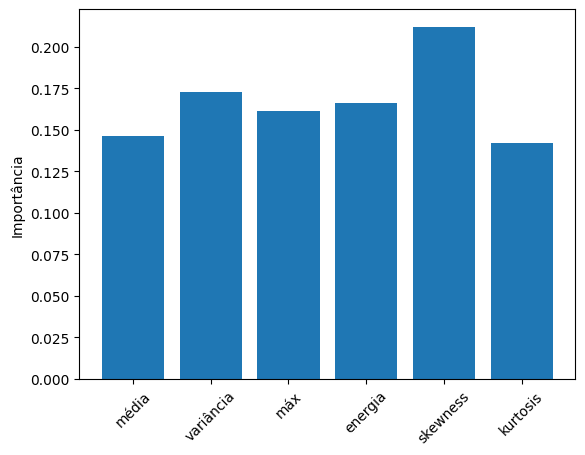

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import matplotlib.pyplot as plt
import pandas as pd

# incerteza via bootsrap ===> já pode fazer o código do bootstrap !!!

X = pd.read_csv('Features3000.csv')

y = pd.read_csv('labels3000.csv')
y = y['soil_type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

modelo = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42)

modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

print("Acurácia:", accuracy_score(y_test,y_pred))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test,y_pred))

print("\nRelatório:")
print(classification_report(y_test,y_pred))

nomes = ['média','variância','máx','energia','skewness','kurtosis']

imp = modelo.feature_importances_

plt.bar(nomes,imp)
plt.ylabel("Importância")
plt.xticks(rotation=45)
plt.show()

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate, KFold

X = pd.read_csv('Features3000.csv')
Y = pd.read_csv('labels3000.csv')
y = Y['pos_y']

model = RandomForestRegressor(n_estimators=100,random_state=0,n_jobs=1)
cv = KFold(n_splits=10,shuffle=True,random_state=1)

results = cross_validate(model,X,y,cv=cv,scoring={'R2':'r2'})

In [8]:
print(results['test_R2'].mean())

0.30219214850085985
